**Note:** fix the two lines in the earlier cells: file name and columns list.

In [ ]:
import sklearn
print(sklearn.__version__)

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("vehicle_sales_demand_dataset.csv")

In [3]:
list(df.columns)

['Date',
 'Store',
 'Vehicle',
 'Category',
 'Region',
 'Fuel_Type',
 'Price',
 'Discount_Percent',
 'Promotion',
 'Inventory_Level',
 'Units_Sold',
 'Sales_Amount']

In [4]:
# data types
df.dtypes

,0
Date,object
Store,object
Vehicle,object
Category,object
Region,object
Fuel_Type,object
Price,float64
Discount_Percent,float64
Promotion,int64
Inventory_Level,int64


In [5]:
# dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Date              3000 non-null   object 
 1   Store             3000 non-null   object 
 2   Vehicle           3000 non-null   object 
 3   Category          3000 non-null   object 
 4   Region            3000 non-null   object 
 5   Fuel_Type         3000 non-null   object 
 6   Price             3000 non-null   float64
 7   Discount_Percent  3000 non-null   float64
 8   Promotion         3000 non-null   int64  
 9   Inventory_Level   3000 non-null   int64  
 10  Units_Sold        3000 non-null   int64  
 11  Sales_Amount      3000 non-null   float64
dtypes: float64(3), int64(3), object(6)
memory usage: 281.4+ KB


In [6]:
# missing values
df.isnull().sum()

,0
Date,0
Store,0
Vehicle,0
Category,0
Region,0
Fuel_Type,0
Price,0
Discount_Percent,0
Promotion,0
Inventory_Level,0


In [7]:
# duplicate records
df.duplicated().sum()

np.int64(0)

## 2. Exploratory Data Analysis (EDA)

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()
print("Numerical variables:", num_cols)
print("Categorical variables:", cat_cols)

Numerical variables: ['Price', 'Discount_Percent', 'Promotion', 'Inventory_Level', 'Units_Sold', 'Sales_Amount']
Categorical variables: ['Date', 'Store', 'Vehicle', 'Category', 'Region', 'Fuel_Type']


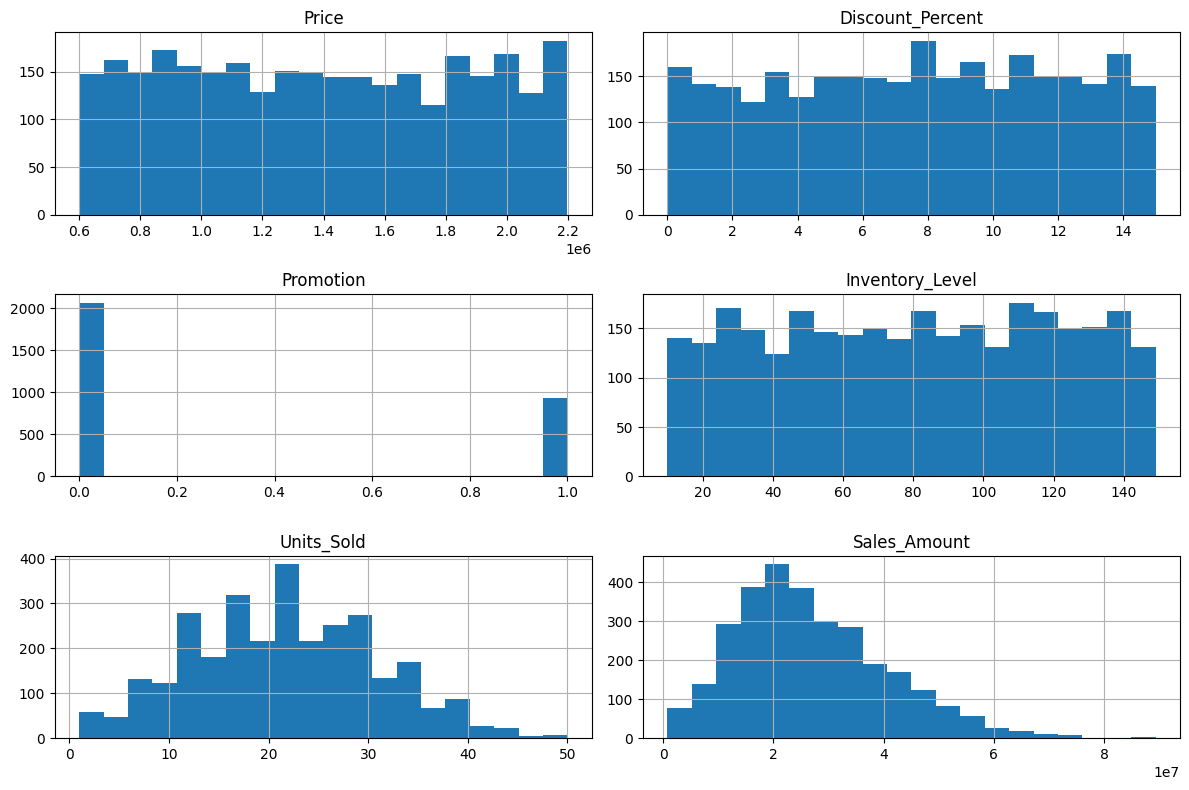

In [9]:
# distribution plots
df[num_cols].hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

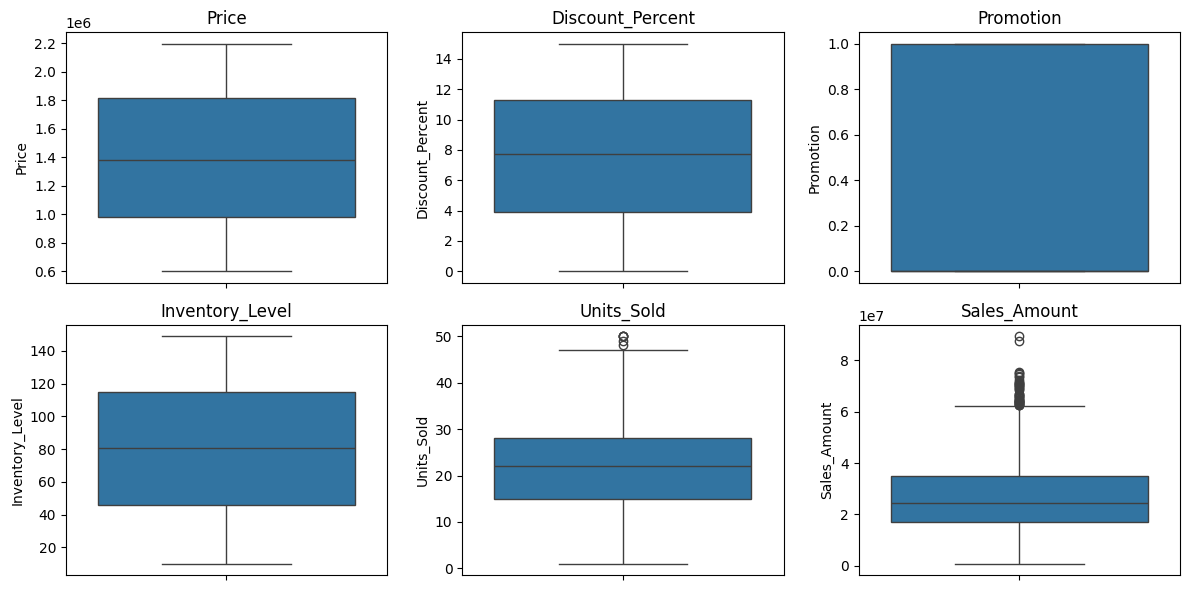

In [10]:
# box plots
plt.figure(figsize=(12, 6))
for i, col in enumerate(num_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

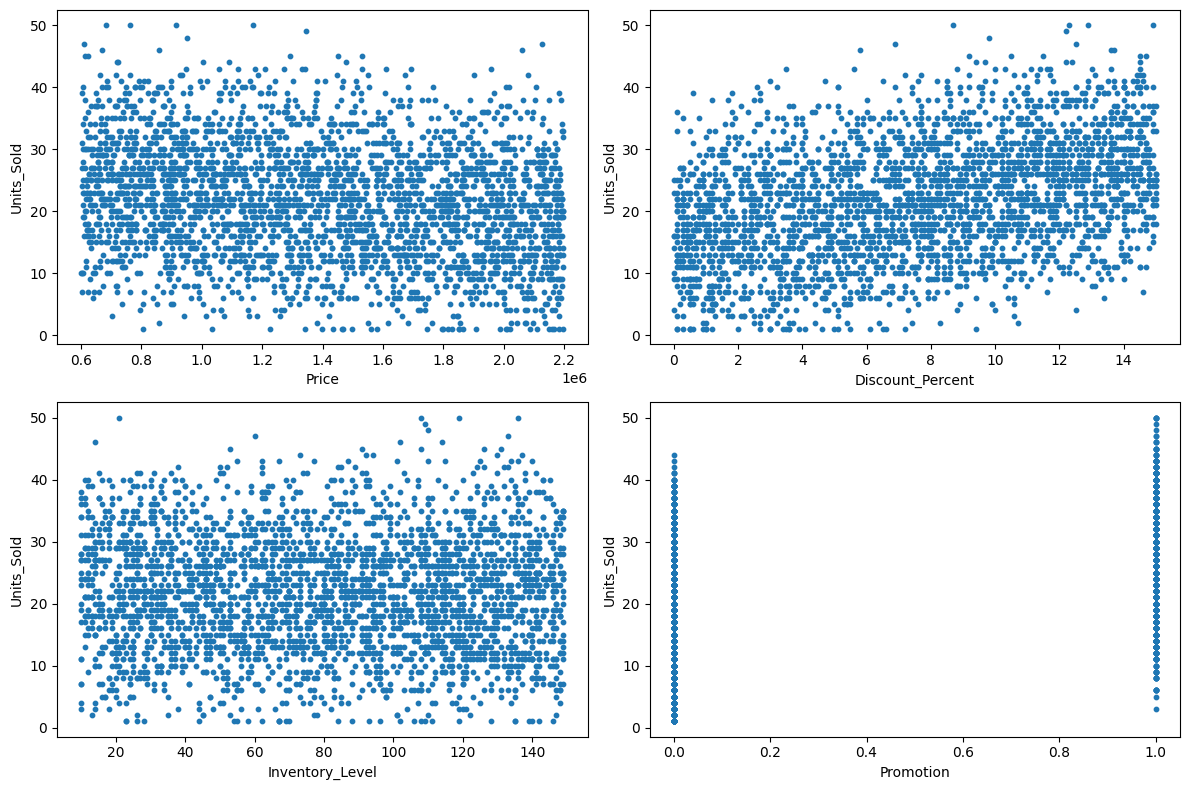

In [11]:
# scatter plots (each feature vs Units_Sold)
features = ['Price', 'Discount_Percent', 'Inventory_Level', 'Promotion']
plt.figure(figsize=(12, 8))
for i, col in enumerate(features):
    plt.subplot(2, 2, i + 1)
    plt.scatter(df[col], df['Units_Sold'], s=10)
    plt.xlabel(col)
    plt.ylabel('Units_Sold')
plt.tight_layout()
plt.show()

## 3. Data Pre-processing

In [12]:
# missing values
print(df.isnull().sum().sum())
df = df.dropna()

0


In [13]:
# duplicate records
df = df.drop_duplicates()
print(df.shape)

(3000, 12)


We have to forecast units **per store per month**, so first we convert the data into monthly data for each store.

In [14]:
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

monthly = df.groupby(['Store', 'Year', 'Month']).agg(
    Units_Sold=('Units_Sold', 'sum'),
    Sales_Records=('Units_Sold', 'count'),
    Avg_Price=('Price', 'mean'),
    Avg_Discount=('Discount_Percent', 'mean'),
    Promotion_Rate=('Promotion', 'mean'),
    Avg_Inventory=('Inventory_Level', 'mean')
).reset_index()
monthly.head()

,Store,Year,Month,Units_Sold,Sales_Records,Avg_Price,Avg_Discount,Promotion_Rate,Avg_Inventory
0,Aurangabad,2023,1,651,27,1.298574e+06,8.488889,0.222222,71.370370
1,Aurangabad,2023,2,417,17,1.171371e+06,7.464706,0.176471,75.176471
2,Aurangabad,2023,3,257,11,1.525195e+06,8.090909,0.272727,84.727273
3,Aurangabad,2023,4,454,17,1.177933e+06,8.229412,0.235294,78.764706
4,Aurangabad,2023,5,414,17,1.514985e+06,8.441176,0.294118,89.000000


In [15]:
# categorical variable -> numerical
data = pd.get_dummies(monthly, columns=['Store'], drop_first=True, dtype=int)
data.head()

,Year,Month,Units_Sold,Sales_Records,Avg_Price,Avg_Discount,Promotion_Rate,Avg_Inventory,Store_Mumbai West,Store_Nagpur Central,Store_Nashik Road,Store_Pune City
0,2023,1,651,27,1.298574e+06,8.488889,0.222222,71.370370,0,0,0,0
1,2023,2,417,17,1.171371e+06,7.464706,0.176471,75.176471,0,0,0,0
2,2023,3,257,11,1.525195e+06,8.090909,0.272727,84.727273,0,0,0,0
3,2023,4,454,17,1.177933e+06,8.229412,0.235294,78.764706,0,0,0,0
4,2023,5,414,17,1.514985e+06,8.441176,0.294118,89.000000,0,0,0,0


## 4. Correlation Analysis

Units_Sold        1.000000
Sales_Records     0.850185
Promotion_Rate    0.313273
Avg_Discount      0.125556
Avg_Inventory    -0.013071
Avg_Price        -0.084495
Month            -0.217673
Name: Units_Sold, dtype: float64


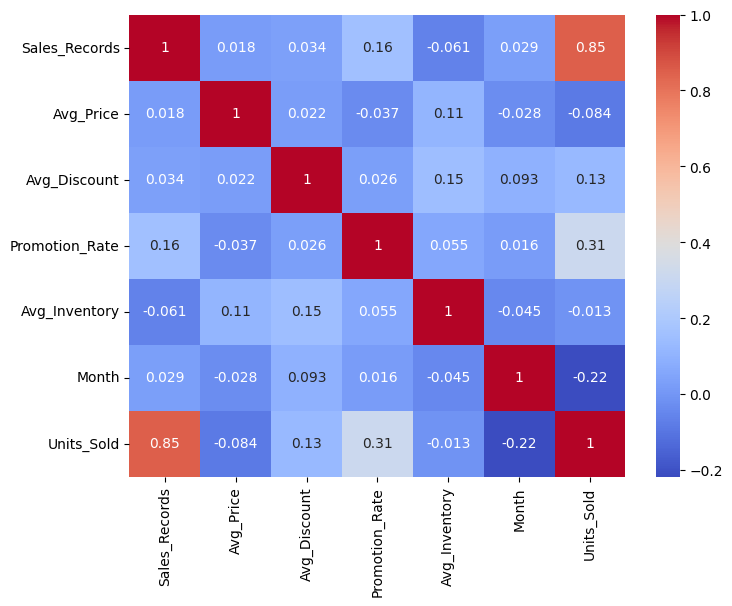

In [16]:
num = ['Sales_Records', 'Avg_Price', 'Avg_Discount', 'Promotion_Rate', 'Avg_Inventory', 'Month', 'Units_Sold']
print(data[num].corr()['Units_Sold'].sort_values(ascending=False))

plt.figure(figsize=(8, 6))
sns.heatmap(data[num].corr(), annot=True, cmap='coolwarm')
plt.show()

## 5. Covariance Analysis

In [17]:
data[num].cov()

,Sales_Records,Avg_Price,Avg_Discount,Promotion_Rate,Avg_Inventory,Month,Units_Sold
Sales_Records,15.977654,8.501469e+03,0.151708,0.073165,-2.451901,0.396648,329.067039
Avg_Price,8501.469460,1.369292e+10,2808.844505,-498.305778,126788.623082,-11436.235522,-957397.581300
Avg_Discount,0.151708,2.808845e+03,1.237892,0.003292,1.632003,0.357119,13.526802
Promotion_Rate,0.073165,-4.983058e+02,0.003292,0.013455,0.064231,0.006439,3.518734
Avg_Inventory,-2.451901,1.267886e+05,1.632003,0.064231,101.507896,-1.578770,-12.752114
Month,0.396648,-1.143624e+04,0.357119,0.006439,-1.578770,11.983240,-72.963687
Units_Sold,329.067039,-9.573976e+05,13.526802,3.518734,-12.752114,-72.963687,9376.251117


## 6. Train-Test Split

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X = data.drop(['Units_Sold', 'Year'], axis=1)
y = data['Units_Sold']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 144
Testing data: 36


Scaling is useful for Ridge and Lasso. Tree based models don't need scaling.

In [19]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 7. Multiple Linear Regression

In [20]:
mlr = LinearRegression()
mlr.fit(X_train, y_train)
mlr_pred = mlr.predict(X_test)
print("Intercept:", round(mlr.intercept_, 2))
print(pd.Series(mlr.coef_, index=X.columns).round(3))

Intercept: 55.66
Month                    -7.369
Sales_Records            20.599
Avg_Price                -0.000
Avg_Discount              8.336
Promotion_Rate          170.442
Avg_Inventory            -0.063
Store_Mumbai West        -9.491
Store_Nagpur Central    -11.421
Store_Nashik Road       -17.247
Store_Pune City         -31.329
dtype: float64


## 8. Ridge Regression

In [21]:
ridge = Ridge(alpha=5.0)
ridge.fit(X_train_scaled, y_train)
ridge_pred = ridge.predict(X_test_scaled)
print("Alpha:", ridge.alpha)
print("Intercept:", round(ridge.intercept_, 2))

Alpha: 5.0
Intercept: 360.25


## 9. Lasso Regression

In [22]:
lasso = Lasso(alpha=0.1)
lasso.fit(X_train_scaled, y_train)
lasso_pred = lasso.predict(X_test_scaled)
print("Alpha:", lasso.alpha)
print("Intercept:", round(lasso.intercept_, 2))

Alpha: 0.1
Intercept: 360.25


## 10. Decision Tree

In [23]:
tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
print("Depth:", tree_model.get_depth())

Depth: 5


## 11. Random Forest

In [24]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("Number of Trees:", rf_model.n_estimators)

Number of Trees: 100


## 12. Model Selection

In [25]:
all_predictions = {
    "Multiple Linear Regression": mlr_pred,
    "Ridge Regression": ridge_pred,
    "Lasso Regression": lasso_pred,
    "Decision Tree Regression": tree_pred,
    "Random Forest Regression": rf_pred
}

results = []
for model_name, prediction in all_predictions.items():
    mae = mean_absolute_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, prediction)
    results.append([model_name, mae, mse, rmse, r2])

result_df = pd.DataFrame(results, columns=["Model", "MAE", "MSE", "RMSE", "R2"])
result_df

,Model,MAE,MSE,RMSE,R2
0,Multiple Linear Regression,30.975442,1580.194856,39.751665,0.856178
1,Ridge Regression,30.500570,1513.692759,38.906205,0.862230
2,Lasso Regression,30.833678,1565.574625,39.567343,0.857508
3,Decision Tree Regression,44.577423,3139.303838,56.029491,0.714274
4,Random Forest Regression,32.413371,1664.075115,40.793077,0.848543


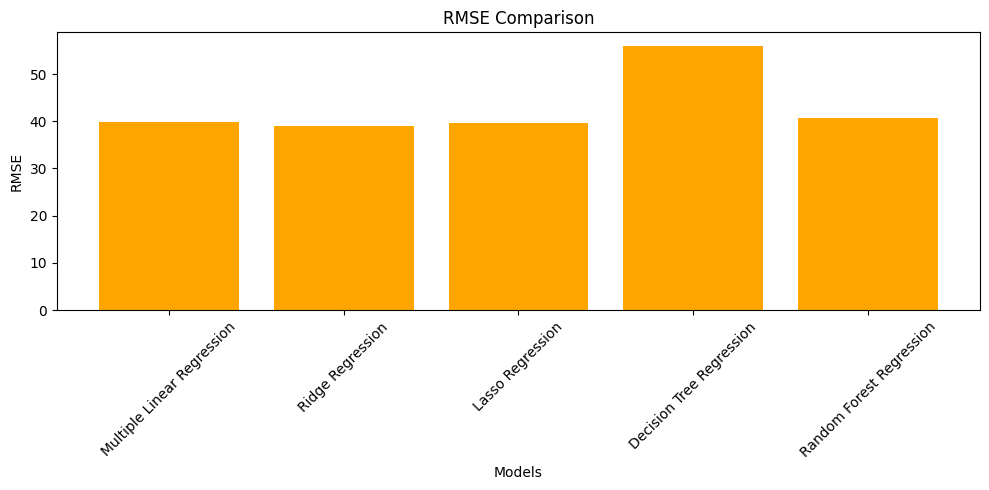

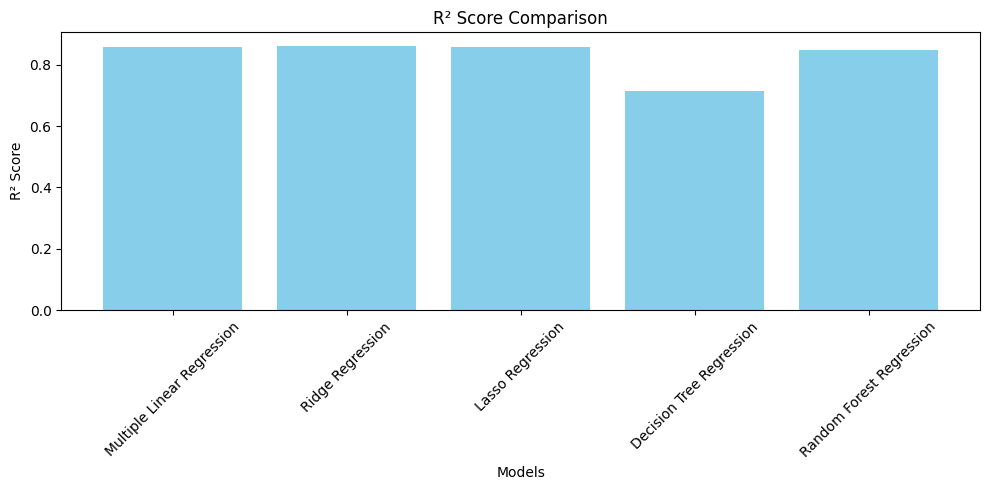

In [26]:
plt.figure(figsize=(10, 5))
plt.bar(result_df["Model"], result_df["RMSE"], color="orange")
plt.xlabel("Models")
plt.ylabel("RMSE")
plt.title("RMSE Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(result_df["Model"], result_df["R2"], color="skyblue")
plt.xlabel("Models")
plt.ylabel("R² Score")
plt.title("R² Score Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
models = {
    'Multiple Linear Regression': mlr,
    'Ridge Regression': ridge,
    'Lasso Regression': lasso,
    'Decision Tree Regression': tree_model,
    'Random Forest Regression': rf_model
}

best_model_name = result_df.loc[result_df['R2'].idxmax()]['Model']
best_model = models[best_model_name]
print("Best Model:", best_model_name)

Best Model: Ridge Regression


## 13. Save the Best Model using Joblib

In [28]:
import joblib

joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(best_model_name, "best_model_name.pkl")
joblib.dump(list(X.columns), "columns.pkl")

['columns.pkl']

In [29]:
# reload and test
model = joblib.load("best_model.pkl")
scalers = joblib.load("scaler.pkl")
name = joblib.load("best_model_name.pkl")
columns = joblib.load("columns.pkl")

def predict_next_month(store, month, sales_records, price, discount, promo_rate, inventory):
    row = pd.DataFrame(0, index=[0], columns=columns)
    row['Month'] = month
    row['Sales_Records'] = sales_records
    row['Avg_Price'] = price
    row['Avg_Discount'] = discount
    row['Promotion_Rate'] = promo_rate
    row['Avg_Inventory'] = inventory
    if 'Store_' + store in columns:
        row['Store_' + store] = 1
    if name in ['Ridge Regression', 'Lasso Regression']:
        row = scalers.transform(row)
    return round(float(model.predict(row)[0]))

print(predict_next_month('Nagpur Central', 7, 17, 1400000, 7.5, 0.5, 100))

397


## 14. Prediction Interface (Streamlit App)

Create `app.py` (provided separately), keep it in the same folder as the 4 `.pkl` files, and run `streamlit run app.py`.

## 15. GitHub Integration

See steps below.

In [30]:
# download the files needed for GitHub from Colab
from google.colab import files
for f in ['best_model.pkl', 'scaler.pkl', 'best_model_name.pkl', 'columns.pkl']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>